# ESMFold2 — Short-chain and long-chain failure tails


## 1. Data source/acquisition

The input manifest specifies401 protein-entity identifiers from a prediction-file inventory. Acquire metadata and coordinates for those identifiers, then apply the stated sequence, experimental and structure-coverage rules. The evaluated count is calculated below. Download PDB sequences and the experimental-entry IDs deposited through2021-09-30 for the sequence-similarity reference; record all response fingerprints.


In [1]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from collections import Counter,defaultdict
import os,json,hashlib,urllib.request,subprocess,tarfile,io,time,socket,math,re
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display,Image
os.environ['OMP_NUM_THREADS']='2';os.environ['MKL_NUM_THREADS']='2';os.environ['OPENBLAS_NUM_THREADS']='2'
ROOT=Path(os.environ.get('ESMFOLD_OPUS_R2_ROOT',str(Path.cwd()/'calculations/opus-r2'))).resolve();ROOT.mkdir(parents=True,exist_ok=True)
RAW=ROOT/'source_data';RAW.mkdir(exist_ok=True)
def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def acquire(url,path,expected=None):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True);receipt=path.with_suffix(path.suffix+'.source.json')
    if path.is_file() and receipt.is_file():
        known=json.loads(receipt.read_text())
        if sha256_file(path)!=known['sha256']:raise ValueError('Cached source bytes changed: '+str(path))
        if expected and known['sha256']!=expected:raise ValueError('Source fingerprint differs')
        return known
    temporary=path.with_suffix(path.suffix+'.partial')
    request=urllib.request.Request(url,headers={'User-Agent':'SPECTRA-protein-analysis/1.0'})
    with urllib.request.urlopen(request,timeout=180) as response,temporary.open('wb') as stream:
        headers={key:response.headers.get(key) for key in ['ETag','Last-Modified','Content-Length']}
        while True:
            block=response.read(1024*1024)
            if not block:break
            stream.write(block)
    digest=sha256_file(temporary)
    if expected and digest!=expected:raise ValueError('Downloaded source fingerprint differs')
    temporary.replace(path)
    record={'url':url,'sha256':digest,'bytes':path.stat().st_size,'headers':headers}
    receipt.write_text(json.dumps(record,indent=2));return record
manifest_path=Path.cwd()/'inputs/protein_entity_ids.json'
if sha256_file(manifest_path)!='35d8452170768a9b10521288603c575849af620787696a32fe1a187f108989d9':raise ValueError('Protein-entity manifest fingerprint differs')
entity_ids=json.loads(manifest_path.read_text())['entity_ids']
print('Acquisition population:',len(entity_ids),'specified protein entities')


Acquisition population: 401 specified protein entities


In [2]:
import gzip,random

def request_json(url,payload,name):
    path=RAW/(name+'.json');receipt=path.with_suffix('.receipt.json')
    query_sha=hashlib.sha256(json.dumps(payload,sort_keys=True).encode()).hexdigest()
    if path.exists() and receipt.exists():
        record=json.loads(receipt.read_text())
        if record['query_sha256']!=query_sha or record['response_sha256']!=sha256_file(path):raise ValueError('Cached API response binding differs')
        return json.loads(path.read_text())
    request=urllib.request.Request(url,data=json.dumps(payload).encode(),headers={'Content-Type':'application/json','User-Agent':'SPECTRA-protein-analysis/1.0'})
    for attempt in range(4):
        try:
            with urllib.request.urlopen(request,timeout=180) as response:data=json.load(response)
            break
        except Exception:
            if attempt==3:raise
            time.sleep(2)
    path.write_text(json.dumps(data));receipt.write_text(json.dumps({'url':url,'query_sha256':query_sha,'response_sha256':sha256_file(path)},indent=2))
    return data
GQL="""query($ids:[String!]!){entries(entry_ids:$ids){rcsb_id exptl{method} rcsb_entry_info{resolution_combined} rcsb_accession_info{deposit_date initial_release_date} polymer_entities{rcsb_id entity_poly{pdbx_seq_one_letter_code_can rcsb_sample_sequence_length rcsb_entity_polymer_type} rcsb_polymer_entity_container_identifiers{auth_asym_ids asym_ids} rcsb_entity_source_organism{ncbi_taxonomy_id ncbi_scientific_name} rcsb_polymer_entity{pdbx_number_of_molecules}}}}"""
entries=sorted({entity.split('_')[0] for entity in entity_ids});wanted=set(entity_ids);metadata=[]
for start in range(0,len(entries),50):
    data=request_json('https://data.rcsb.org/graphql',{'query':GQL,'variables':{'ids':entries[start:start+50]}},f'entity_metadata_{start:04}')
    if data.get('errors'):raise ValueError(data['errors'])
    for entry in data['data']['entries']:
        if entry is None:continue
        resolution=(entry.get('rcsb_entry_info') or {}).get('resolution_combined') or []
        dates=entry.get('rcsb_accession_info') or {};method=(entry.get('exptl') or [{}])[0].get('method')
        for entity in entry.get('polymer_entities') or []:
            if entity['rcsb_id'] not in wanted:continue
            sequence_info=entity.get('entity_poly') or {};identifiers=entity.get('rcsb_polymer_entity_container_identifiers') or {};organisms=entity.get('rcsb_entity_source_organism') or []
            metadata.append({'entity_id':entity['rcsb_id'],'entry_id':entry['rcsb_id'],'sequence':sequence_info.get('pdbx_seq_one_letter_code_can'),'polymer_type':sequence_info.get('rcsb_entity_polymer_type'),'auth_asym_ids':identifiers.get('auth_asym_ids'),'method':method,'resolution':resolution[0] if resolution else np.nan,'deposit_date':dates.get('deposit_date'),'release_date':dates.get('initial_release_date'),'n_copies':(entity.get('rcsb_polymer_entity') or {}).get('pdbx_number_of_molecules'),'organism':organisms[0].get('ncbi_scientific_name') if organisms else None})
metadata=pd.DataFrame(metadata)
if set(metadata.entity_id)!=wanted:raise ValueError('One or more specified entities were not returned by RCSB')
def get_entry(entry):return entry,acquire('https://files.rcsb.org/download/'+entry+'.cif.gz',RAW/(entry+'.cif.gz'))
with ThreadPoolExecutor(max_workers=2) as pool:structure_sources=dict(pool.map(get_entry,entries))
reference_entries=[]
for start in range(0,500000,10000):
    payload={'query':{'type':'group','logical_operator':'and','nodes':[{'type':'terminal','service':'text','parameters':{'attribute':'rcsb_accession_info.deposit_date','operator':'less_or_equal','value':'2021-09-30'}},{'type':'terminal','service':'text','parameters':{'attribute':'rcsb_entry_info.polymer_entity_count_protein','operator':'greater','value':0}}]},'return_type':'entry','request_options':{'paginate':{'start':start,'rows':10000},'results_content_type':['experimental']}}
    response=request_json('https://search.rcsb.org/rcsbsearch/v2/query',payload,f'precutoff_entries_{start:06}')
    reference_entries.extend(row['identifier'].lower() for row in response.get('result_set',[]))
    if start+10000>=response['total_count']:break
if len(reference_entries)<10000:raise ValueError('Pre-cutoff reference query is incomplete')
sequence_source=acquire('https://files.wwpdb.org/pub/pdb/derived_data/pdb_seqres.txt.gz',RAW/'pdb_seqres.txt.gz')
display(metadata[['entity_id','method','resolution','deposit_date','n_copies']]);print('Pre-cutoff experimental entries:',len(reference_entries))


,entity_id,method,resolution,deposit_date,n_copies
0,10EE_1,X-RAY DIFFRACTION,1.650,2026-01-15T00:00:00Z,1
1,11KO_1,X-RAY DIFFRACTION,1.580,2026-03-02T00:00:00Z,1
2,22FK_1,X-RAY DIFFRACTION,1.898,2026-01-08T00:00:00Z,5
3,36BZ_1,X-RAY DIFFRACTION,1.770,2026-05-29T00:00:00Z,2
4,5SC9_1,X-RAY DIFFRACTION,1.685,2021-12-01T00:00:00Z,8
...,...,...,...,...,...
396,9YUD_1,X-RAY DIFFRACTION,2.700,2025-10-22T00:00:00Z,2
397,9ZYE_1,X-RAY DIFFRACTION,2.700,2026-01-05T00:00:00Z,2
398,9YGK_1,X-RAY DIFFRACTION,1.950,2025-09-29T00:00:00Z,2
399,9VN8_1,X-RAY DIFFRACTION,1.650,2025-06-30T00:00:00Z,1


Pre-cutoff experimental entries: 186505


## 2. Data processing

Require X-ray structures at≤3.5Å, deposition after2021-09-30, length40–1023, standard residues with≤2%X, at least30 experimental C-alpha atoms and≥40% coordinate coverage. Collapse exact duplicates and40%-identity clusters, keeping the best-resolution member. Extract the first specified author chain. Calculate amino-acid entropy and composition.


In [3]:
import gemmi
from Bio.SeqUtils import seq3
STD=set('ACDEFGHIKLMNPQRSTVWY');ALLOWED=STD|{'X'}
metadata['sequence']=metadata.sequence.fillna('').str.upper().str.strip()
metadata['len']=metadata.sequence.str.len()
eligibility=(metadata.polymer_type.eq('Protein') & metadata.method.eq('X-RAY DIFFRACTION') & metadata.resolution.le(3.5) & metadata.deposit_date.gt('2021-09-30') & metadata['len'].between(40,1023) & metadata.auth_asym_ids.map(bool) & metadata.sequence.map(lambda sequence:bool(sequence) and set(sequence).issubset(ALLOWED) and sequence.count('X')/len(sequence)<=.02))
features=metadata[eligibility].copy()
features=features.sort_values(['resolution','entity_id']).drop_duplicates('sequence').sort_values('entity_id').reset_index(drop=True)
CHAIN_DIR=ROOT/'native';CHAIN_DIR.mkdir(exist_ok=True)
def chain_coordinates(path,chain_id,fallback=False):
    model=gemmi.read_structure(str(path))[0]
    def read(chain):
        sequence=[];coordinates=[]
        for residue in chain:
            aa=gemmi.find_tabulated_residue(residue.name).one_letter_code.upper()
            if aa not in STD:continue
            atoms=[atom for atom in residue if atom.name=='CA' and atom.altloc in ['\x00','A']]
            if atoms:
                atom=atoms[0];sequence.append(aa);coordinates.append([atom.pos.x,atom.pos.y,atom.pos.z])
        return ''.join(sequence),np.asarray(coordinates,float)
    chain=model.find_chain(str(chain_id));result=read(chain) if chain is not None else ('',np.empty((0,3)))
    if not result[0] and fallback:result=max((read(chain) for chain in model),key=lambda item:len(item[0]))
    return result

def write_ca_pdb(sequence,coordinates,path):
    lines=[]
    for i,(aa,xyz) in enumerate(zip(sequence,coordinates),1):
        x,y,z=xyz;lines.append(f'ATOM  {i:5d}  CA  {seq3(aa).upper():>3s} A{i:4d}    {x:8.3f}{y:8.3f}{z:8.3f}  1.00 50.00           C')
    Path(path).write_text('\n'.join(lines+['TER','END'])+'\n')
native_records=[]
for row in features.itertuples():
    sequence,coords=chain_coordinates(RAW/(row.entry_id+'.cif.gz'),row.auth_asym_ids[0])
    path=CHAIN_DIR/(row.entity_id+'.pdb');write_ca_pdb(sequence,coords,path)
    native_records.append({'entity_id':row.entity_id,'native_ca':len(sequence),'native_coverage':len(sequence)/row.len,'target_chain_path':str(path),'native_auth_chain':row.auth_asym_ids[0]})
features=features.merge(pd.DataFrame(native_records),on='entity_id',validate='one_to_one')
features=features[features.native_ca.ge(30)&features.native_coverage.ge(.4)].copy()
features['sequence_sha256']=features.sequence.map(lambda value:hashlib.sha256(value.encode()).hexdigest())
def composition(sequence):
    counts=Counter(sequence);n=len(sequence)
    return {'comp_entropy_bits':round(-sum(count/n*math.log2(count/n) for count in counts.values()),3),'max_aa_frac':round(max(counts.values())/n,3),'top3_aa_frac':round(sum(sorted(counts.values(),reverse=True)[:3])/n,3)}
for column in ['comp_entropy_bits','max_aa_frac','top3_aa_frac']:features[column]=features.sequence.map(lambda sequence:composition(sequence)[column])
TOOLS=ROOT/'third_party';TOOLS.mkdir(exist_ok=True)
MMSEQS=TOOLS/'mmseqs/bin/mmseqs'
if not MMSEQS.exists():
    archive=TOOLS/'mmseqs18.tar.gz';acquire('https://github.com/soedinglab/MMseqs2/releases/download/18-8cc5c/mmseqs-linux-avx2.tar.gz',archive)
    with tarfile.open(archive,'r:gz') as bundle:bundle.extractall(TOOLS,filter='data')
print('Sequence search implementation:',subprocess.check_output([str(MMSEQS),'version'],text=True).strip())
QUERY=ROOT/'query.fasta'
QUERY.write_text(''.join('>'+row.entity_id+'\n'+row.sequence+'\n' for row in features.itertuples()))
cluster_prefix=ROOT/'cluster';cluster_signature={'query_sha256':sha256_file(QUERY),'identity':.4,'coverage':.8,'coverage_mode':1,'binary_sha256':sha256_file(MMSEQS)}
cluster_receipt=ROOT/'cluster.receipt.json'
cluster_table=ROOT/'cluster_cluster.tsv'
if not cluster_table.exists() or not cluster_receipt.exists() or json.loads(cluster_receipt.read_text()).get('binding')!=cluster_signature:
    subprocess.run([str(MMSEQS),'easy-cluster',str(QUERY),str(cluster_prefix),str(ROOT/'cluster_tmp'),'--min-seq-id','0.4','-c','0.8','--cov-mode','1','--threads','2','-v','1'],check=True)
    cluster_receipt.write_text(json.dumps({'binding':cluster_signature,'output_sha256':sha256_file(cluster_table)}))
if sha256_file(cluster_table)!=json.loads(cluster_receipt.read_text())['output_sha256']:raise ValueError('Sequence-cluster output fingerprint differs')
cluster_rows=pd.read_csv(cluster_table,sep='\t',header=None,names=['cluster','entity_id'])
features=features.merge(cluster_rows,on='entity_id',validate='one_to_one').sort_values(['resolution','entity_id']).drop_duplicates('cluster').sort_values('entity_id').reset_index(drop=True)
QUERY.write_text(''.join('>'+row.entity_id+'\n'+row.sequence+'\n' for row in features.itertuples()))
precutoff=set(reference_entries);seen=set();REFERENCE_FASTA=ROOT/'precutoff_pdb.fasta'
with gzip.open(RAW/'pdb_seqres.txt.gz','rt') as source,REFERENCE_FASTA.open('w') as destination:
    header=None
    for line in source:
        if line.startswith('>'):header=line[1:].strip()
        elif header is not None:
            sequence=line.strip();parts=header.split();chain_id=parts[0];header=None
            if 'mol:protein' not in parts or chain_id.split('_')[0].lower() not in precutoff or not 30<=len(sequence)<=3000 or sequence in seen:continue
            seen.add(sequence);destination.write('>'+chain_id+'\n'+sequence+'\n')
print('Input population:',len(entity_ids),'eligible nonredundant chains:',len(features),'reference sequences:',len(seen))
display(features[['entity_id','len','resolution','native_ca','native_coverage','comp_entropy_bits','n_copies']])


Sequence search implementation: 8cc5ce367b5638c4306c2d7cfc652dd099a4643f


Input population: 401 eligible nonredundant chains: 400 reference sequences: 126678


,entity_id,len,resolution,native_ca,native_coverage,comp_entropy_bits,n_copies
0,10EE_1,391,1.650,354,0.905371,4.190,1
1,11KO_1,541,1.580,530,0.979667,4.140,1
2,22FK_1,106,1.898,106,1.000000,3.966,5
3,36BZ_1,193,1.770,183,0.948187,4.068,2
4,5SC9_1,447,1.685,414,0.926174,4.042,8
...,...,...,...,...,...,...,...
395,9YC2_1,105,1.400,105,1.000000,4.094,1
396,9YGK_1,285,1.950,272,0.954386,3.957,2
397,9YIS_1,487,2.180,467,0.958932,4.164,6
398,9YUD_1,443,2.700,355,0.801354,4.172,2


## 3. Axis definition and level construction

Construct the seven length levels40–127,128–199,200–287,288–399,400–511,512–767 and768–1023; the last is exploratory. Search the pre-cutoff sequence database with sensitivity7.5 and up to500 hits/query. Maximum identity uses hits with query coverage≥0.5, or the maximum among all hits if none meets coverage. Homology controls use0–30%,30–60%,60–90% and90–100%.


In [4]:
LEVEL_RANGES=[('L1_40-127',40,127),('L2_128-199',128,199),('L3_200-287',200,287),('L4_288-399',288,399),('L5_400-511',400,511),('L6_512-767',512,767),('L7_768-1023',768,1023)]
LEVELS=[item[0] for item in LEVEL_RANGES];PRIMARY=LEVELS[:6]
def length_level(length):return next(label for label,low,high in LEVEL_RANGES if low<=length<=high)
features['level']=features['len'].map(length_level)
search_path=ROOT/'query_vs_reference.tsv';search_receipt=ROOT/'search.receipt.json'
search_binding={'query_sha256':sha256_file(QUERY),'reference_sha256':sha256_file(REFERENCE_FASTA),'binary_sha256':sha256_file(MMSEQS),'sensitivity':7.5,'max_seqs':500}
if not search_path.exists() or not search_receipt.exists() or json.loads(search_receipt.read_text()).get('binding')!=search_binding:
    subprocess.run([str(MMSEQS),'easy-search',str(QUERY),str(REFERENCE_FASTA),str(search_path),str(ROOT/'search_tmp'),'-s','7.5','--max-seqs','500','-a','--format-output','query,target,fident,alnlen,qcov,tcov,evalue,bits','--threads','2','-v','1'],check=True)
    search_receipt.write_text(json.dumps({'binding':search_binding,'output_sha256':sha256_file(search_path)}))
if sha256_file(search_path)!=json.loads(search_receipt.read_text())['output_sha256']:raise ValueError('Alignment table fingerprint differs')
hits=pd.read_csv(search_path,sep='\t',header=None,names=['query','target','fident','alnlen','qcov','tcov','evalue','bits'])
hit_groups={query:group for query,group in hits.groupby('query',sort=False)}
records=[]
for entity in features.entity_id:
    matches=hit_groups.get(entity,pd.DataFrame(columns=hits.columns));covered=matches[matches.qcov.ge(.5)]
    eligible=covered if len(covered) else matches
    best=eligible.loc[eligible.fident.idxmax()] if len(eligible) else None
    records.append({'entity_id':entity,'max_train_ident':round(float(best.fident)*100,2) if best is not None else 0,'n_homologs_30':int((matches.fident.ge(.3)&matches.qcov.ge(.5)).sum()),'n_homologs_50':int((matches.fident.ge(.5)&matches.qcov.ge(.5)).sum()),'best_template':str(best.target) if best is not None else None,'best_template_ident':round(float(best.fident)*100,2) if best is not None else np.nan,'best_template_qcov':round(float(best.qcov),3) if best is not None else np.nan})
features=features.merge(pd.DataFrame(records),on='entity_id',validate='one_to_one')
features['homology_level']=pd.cut(features.max_train_ident,[0,30,60,90,101],right=False,labels=['0–<30','30–<60','60–<90','90–100'])
display(features[['entity_id','len','level','max_train_ident','homology_level','best_template']])
display(features.groupby('level').agg(n=('entity_id','size'),median_length=('len','median'),median_identity=('max_train_ident','median')))


,entity_id,len,level,max_train_ident,homology_level,best_template
0,10EE_1,391,L4_288-399,43.4,30–<60,1kyw_A
1,11KO_1,541,L6_512-767,100.0,90–100,1aq2_A
2,22FK_1,106,L1_40-127,95.2,90–100,4i8b_A
3,36BZ_1,193,L2_128-199,98.4,90–100,3vvx_A
4,5SC9_1,447,L5_400-511,81.7,60–<90,4ip7_A
...,...,...,...,...,...,...
395,9YC2_1,105,L1_40-127,46.5,30–<60,5wpb_A
396,9YGK_1,285,L3_200-287,61.9,60–<90,5vct_A
397,9YIS_1,487,L5_400-511,57.9,30–<60,2bma_A
398,9YUD_1,443,L5_400-511,98.8,90–100,1so2_A


,n,median_length,median_identity
level,,,
L1_40-127,66,95.5,83.30
L2_128-199,68,165.0,99.30
L3_200-287,68,248.5,95.35
L4_288-399,66,349.0,70.80
L5_400-511,62,454.5,77.00
L6_512-767,54,604.0,63.55
L7_768-1023,16,807.5,70.20


## 4. Model evaluation

Predict the eligible input sequences with ESMFold2, seed0,3 loops,50 diffusion steps and1 sample, using the pinned Biohub weights through Transformers5.22.2. Reuse only predictions whose input/model/settings binding and coordinate hash verify. Score each prediction against its native chain with US-align; score the closest pre-cutoff template on the same target. A missing template remains uncovered.


In [5]:
# Hugging Face Transformers converter, Apache-2.0, commit3d87599b23ff5f630de770e08eeed64950e25a9e.
import argparse
import glob
import json
import os
import torch
from huggingface_hub import HfApi, save_torch_state_dict, snapshot_download
from safetensors.torch import load_file
from transformers import EsmcConfig, EsmcTokenizer
esmc__LEGACY_FIELDS = ('vocab_size', 'initializer_range', 'pad_token_id', 'tie_word_embeddings', 'mask_token_id', 'classifier_dropout')
esmc__LEGACY_RENAMES = {'hidden_size': 'd_model', 'num_attention_heads': 'n_heads', 'num_hidden_layers': 'n_layers'}
esmc__LEGACY_DROP_KEYS = {'architectures', 'model_type', 'transformers_version'}
esmc__WEIGHT_KEY_RENAMES = (('embed.', 'embed_tokens.'), ('transformer.blocks.', 'layers.'), ('transformer.norm.', 'norm.'), ('attn.layernorm_qkv.layer_norm_weight', 'input_layernorm.weight'), ('attn.layernorm_qkv.layer_norm_bias', 'input_layernorm.bias'), ('attn.q_ln.', 'self_attn.q_norm.'), ('attn.k_ln.', 'self_attn.k_norm.'), ('attn.out_proj.', 'self_attn.o_proj.'), ('ffn.layer_norm_weight', 'post_attention_layernorm.weight'), ('ffn.layer_norm_bias', 'post_attention_layernorm.bias'), ('ffn.fc2_weight', 'mlp.down_proj.weight'), ('lm_head.0.', 'lm_head.dense.'), ('lm_head.2.', 'lm_head.layer_norm.'), ('lm_head.3.', 'lm_head.decoder.'))
esmc__PACKED_QKV_SUFFIX = 'attn.layernorm_qkv.weight'
esmc__PACKED_GATE_UP_SUFFIX = 'ffn.fc1_weight'
esmc__WEIGHT_KEY_DROP_SUFFIX = '_extra_state'

def esmc__read_json(directory: str) -> dict:
    with open(os.path.join(directory, 'config.json')) as f:
        return json.load(f)

def esmc_build_esmc_config_dict(esmc_dir: str) -> dict:
    old = esmc__read_json(esmc_dir)
    config = {field: old[field] for field in esmc__LEGACY_FIELDS if field in old}
    for port_field, legacy_field in esmc__LEGACY_RENAMES.items():
        config[port_field] = old[legacy_field]
    config['intermediate_size'] = int((8 / 3 * config['hidden_size'] + 255) // 256 * 256)
    if 'dtype' in old:
        config['dtype'] = old['dtype']
    mapped = {*esmc__LEGACY_FIELDS, *esmc__LEGACY_RENAMES.values(), 'dtype'}
    unexpected = set(old) - (mapped | esmc__LEGACY_DROP_KEYS)
    if unexpected:
        raise ValueError(f'unmapped fields in the source ESMC config: {sorted(unexpected)}')
    return config

def esmc_build_config(esmc_dir: str) -> EsmcConfig:
    config = esmc_build_esmc_config_dict(esmc_dir)
    config['architectures'] = ['EsmcForMaskedLM']
    return EsmcConfig.from_dict(config)

def esmc_convert_esmc_state_dict(state_dict: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    converted: dict[str, torch.Tensor] = {}
    for key, tensor in state_dict.items():
        if key.endswith(esmc__WEIGHT_KEY_DROP_SUFFIX):
            continue
        for old, new in esmc__WEIGHT_KEY_RENAMES:
            key = key.replace(old, new)
        if key.endswith(esmc__PACKED_QKV_SUFFIX):
            base = key[:-len(esmc__PACKED_QKV_SUFFIX)]
            q, k, v = (chunk.clone() for chunk in torch.chunk(tensor, 3, dim=0))
            converted.update({base + 'self_attn.q_proj.weight': q, base + 'self_attn.k_proj.weight': k, base + 'self_attn.v_proj.weight': v})
        elif key.endswith(esmc__PACKED_GATE_UP_SUFFIX):
            base = key[:-len(esmc__PACKED_GATE_UP_SUFFIX)]
            gate, up = (chunk.clone() for chunk in torch.chunk(tensor, 2, dim=0))
            converted.update({base + 'mlp.gate_proj.weight': gate, base + 'mlp.up_proj.weight': up})
        else:
            converted[key] = tensor
    return converted

def esmc__load_state_dict(directory: str) -> dict[str, torch.Tensor]:
    shards = sorted(glob.glob(os.path.join(directory, '*.safetensors')))
    if not shards:
        raise FileNotFoundError(f'no *.safetensors weights found in {directory}')
    state_dict: dict[str, torch.Tensor] = {}
    for shard in shards:
        state_dict.update(load_file(shard))
    return state_dict

def esmc_save_tokenizer(output_dir: str) -> None:
    EsmcTokenizer().save_pretrained(output_dir)


In [6]:
# Hugging Face Transformers converter, Apache-2.0, commit3d87599b23ff5f630de770e08eeed64950e25a9e.
import argparse
import glob
import json
import os
import re
import torch
from huggingface_hub import HfApi, save_torch_state_dict, snapshot_download
from safetensors.torch import load_file
from transformers import EsmcTokenizer, EsmFold2Config, EsmFold2Model
fold__LEGACY_FIELDS = ('num_loops', 'structure_head.diffusion_module.sigma_data', 'structure_head.diffusion_module.fourier_dim', 'structure_head.gamma_0', 'structure_head.gamma_min', 'structure_head.noise_scale', 'structure_head.step_scale', 'structure_head.inference_num_steps', 'confidence_head.num_plddt_bins', 'confidence_head.num_pde_bins', 'confidence_head.num_pae_bins', 'confidence_head.min_dist', 'confidence_head.max_dist', 'confidence_head.distogram_bins', 'lm_encoder.lm_dropout', 'lm_encoder.per_loop_lm_dropout')
fold__LEGACY_RENAMES = {'hidden_size': 'd_single', 'pairwise_hidden_size': 'd_pair', 'single_inputs_size': 'inputs.d_inputs', 'sliding_window': 'inputs.atom_encoder.swa_window_size', 'folding_trunk_num_hidden_layers': 'folding_trunk.n_layers', 'parcae_num_coda_layers': 'parcae.coda_n_layers', 'num_relative_residx_bins': 'n_relative_residx_bins', 'num_relative_chain_bins': 'n_relative_chain_bins', 'atom_encoder.hidden_size': 'inputs.atom_encoder.d_atom', 'atom_encoder.num_hidden_layers': 'inputs.atom_encoder.n_blocks', 'atom_encoder.num_attention_heads': 'inputs.atom_encoder.n_heads', 'atom_encoder.spatial_rope_base_frequency': 'inputs.atom_encoder.spatial_rope_base_frequency', 'atom_encoder.num_spatial_rope_pairs_per_axis': 'inputs.atom_encoder.n_spatial_rope_pairs_per_axis', 'atom_encoder.num_uid_rope_pairs': 'inputs.atom_encoder.n_uid_rope_pairs', 'atom_encoder.uid_rope_base_frequency': 'inputs.atom_encoder.uid_rope_base_frequency', 'structure_head.diffusion_module.atom_encoder.hidden_size': 'structure_head.diffusion_module.c_atom', 'structure_head.diffusion_module.atom_encoder.num_hidden_layers': 'structure_head.diffusion_module.atom_num_blocks', 'structure_head.diffusion_module.atom_encoder.num_attention_heads': 'structure_head.diffusion_module.atom_num_heads', 'structure_head.diffusion_module.hidden_size': 'structure_head.diffusion_module.c_token', 'structure_head.diffusion_module.num_hidden_layers': 'structure_head.diffusion_module.token_num_blocks', 'structure_head.diffusion_module.num_attention_heads': 'structure_head.diffusion_module.token_num_heads', 'structure_head.num_distogram_bins': 'structure_head.distogram_bins', 'structure_head.num_diffusion_samples': 'num_diffusion_samples', 'structure_head.inference_sigma_max_ratio': 'structure_head.inference_s_max', 'structure_head.inference_sigma_min_ratio': 'structure_head.inference_s_min', 'structure_head.inference_exponent': 'structure_head.inference_p', 'confidence_head.num_hidden_layers': 'confidence_head.folding_trunk.n_layers', 'msa_encoder.hidden_size': 'msa_encoder.d_msa', 'msa_encoder.outer_hidden_size': 'msa_encoder.d_hidden', 'msa_encoder.num_hidden_layers': 'msa_encoder.n_layers', 'msa_encoder.num_attention_heads': 'msa_encoder.n_heads_msa', 'msa_encoder.head_dim': 'msa_encoder.msa_head_width', 'lm_encoder.num_hidden_layers': 'lm_encoder.n_layers'}
fold__LEGACY_PORT_PATHS = (*fold__LEGACY_FIELDS, *fold__LEGACY_RENAMES)
fold__LEGACY_WIDTH_INPUTS = {'inputs.atom_encoder.expansion_ratio', 'structure_head.diffusion_module.transition_multiplier'}
fold__LEGACY_TRANSITION_EXPANSION_RATIO = 4
fold__LEGACY_DROP_PATHS = {'architectures', 'model_type', 'transformers_version', 'type', 'esmc_id', 'inputs.atom_encoder.d_token', 'lm_d_model', 'lm_num_layers', 'lm_dropout', 'disable_msa_features', 'force_lm_dropout_during_inference', 'folding_trunk.n_heads', 'folding_trunk.dropout', 'structure_head.train_noise_log_mean', 'structure_head.train_noise_log_std', 'structure_head.diffusion_module.c_z', 'structure_head.diffusion_module.c_s_inputs', 'structure_head.diffusion_module.relpos_r_max', 'structure_head.diffusion_module.relpos_s_max', 'msa_encoder.enabled', 'msa_encoder_overwrite', 'lm_encoder.enabled', 'confidence_head.enabled', 'confidence_head.folding_trunk.n_heads', 'confidence_head.folding_trunk.dropout', 'parcae.enabled', 'parcae.max_steps', 'parcae.min_steps', 'parcae.poisson_mean'}
fold__WEIGHT_KEY_RENAMES = (('inputs_embedder.atom_attention_encoder.', 'input_embedder.atom_encoder.'), ('structure_head.diffusion_module.', 'structure_head.'), ('structure_head.atom_encoder.coords_linear.', 'structure_head.coords_linear.'), ('.atom_transformer.', '.'), ('._engine.', '.'), ('.blocks.', '.layers.'), ('.attn.', '.self_attn.'), ('.w_up.', '.gate_up_proj.'), ('.w_down.', '.down_proj.'), ('.lin_swish.', '.mlp.gate_up_proj.'), ('.lin_out.', '.mlp.down_proj.'), ('.ffn.w12.', '.mlp.gate_up_proj.'), ('.ffn.w3.', '.mlp.down_proj.'), ('.ffn.', '.mlp.'), ('fourier.w', 'fourier.frequencies'), ('fourier.b', 'fourier.phases'), ('parcae_', 'parcae.'), ('parcae.log_a', 'parcae.log_state_decay'), ('parcae.b_cont', 'parcae.input_matrix_continuous'), ('parcae.readout.', 'parcae.out_proj.'), ('parcae.coda.', 'parcae.output_stack.'), ('output_mlp.0.', 'output_fc1.'), ('output_mlp.2.', 'output_fc2.'), ('adaln_modulation.1.', 'adaln_linear.'), ('adaln.s_gate.', 'adaln.gate_proj.'), ('adaln.s_shift.', 'adaln.shift_proj.'), ('adaln.s_scale', 'adaln.cond_norm.weight'), ('base_z_linear.0.', 'pair_input_norm.'), ('base_z_linear.1.', 'pair_proj.'), ('base_z_mlp.0.', 'single_to_pair.'), ('base_z_mlp.1.', 'pair_output_norm.'), ('base_z_combine', 'layer_weights'), ('compute_bias.0.', 'bias_norm.'), ('compute_bias.1.', 'bias_proj.'), ('.z_input_norm.', '.pair_input_norm.'), ('.z_proj.', '.pair_proj.'), ('.z_transitions.0.', '.pair_transition_0.'), ('.z_transitions.1.', '.pair_transition_1.'), ('.s_input_norm.', '.single_input_norm.'), ('.s_proj.', '.single_proj.'), ('.s_transitions.0.', '.single_transition_0.'), ('.s_transitions.1.', '.single_transition_1.'), ('.s_to_token.', '.single_to_token.'), ('.s_step_norm.', '.single_step_norm.'), ('.g_proj.', '.gate_proj.'), ('z_init_1.', 'input_embedder.pair_init_1.'), ('z_init_2.', 'input_embedder.pair_init_2.'), ('rel_pos.', 'input_embedder.rel_pos.'), ('token_bonds.', 'input_embedder.token_bonds.'), ('outer_product_mean.W.', 'outer_product_mean.input_proj.'), ('outer_product_mean.Wout.', 'outer_product_mean.output_proj.'), ('msa_pair_weighted_averaging.Wv.', 'msa_pair_weighted_averaging.v_proj.'), ('msa_pair_weighted_averaging.Wgate.', 'msa_pair_weighted_averaging.gate_proj.'), ('msa_pair_weighted_averaging.Wout.', 'msa_pair_weighted_averaging.o_proj.'), ('confidence_head.plddt_ln.', 'confidence_head.plddt_layernorm.'), ('confidence_head.pae_ln.', 'confidence_head.pae_layernorm.'), ('confidence_head.pde_ln.', 'confidence_head.pde_layernorm.'), ('confidence_head.resolved_ln.', 'confidence_head.resolved_layernorm.'), ('confidence_head.s_inputs_norm.', 'confidence_head.input_embedder.single_inputs_norm.'), ('confidence_head.z_norm.', 'confidence_head.input_embedder.pair_norm.'), ('confidence_head.s_to_z.', 'confidence_head.input_embedder.single_to_pair.'), ('confidence_head.s_to_z_transpose.', 'confidence_head.input_embedder.single_to_pair_transpose.'), ('confidence_head.s_to_z_prod_in1.', 'confidence_head.input_embedder.single_to_pair_prod_in1.'), ('confidence_head.s_to_z_prod_in2.', 'confidence_head.input_embedder.single_to_pair_prod_in2.'), ('confidence_head.s_to_z_prod_out.', 'confidence_head.input_embedder.single_to_pair_prod_out.'))
fold__PACKED_QKV_SUFFIX = 'self_attn.Wqkv.weight'
fold__WEIGHT_KEY_DROPS = ('confidence_head.s_norm.', 'confidence_head.s_inputs_to_single.', 'confidence_head.s_input_to_s.')

def fold__read_json(directory: str) -> dict:
    with open(os.path.join(directory, 'config.json')) as f:
        return json.load(f)

def fold__get_path(cfg: dict, path: str):
    node = cfg
    for part in path.split('.'):
        node = node[part]
    return node

def fold__leaf_paths(cfg: dict, prefix: str='') -> set[str]:
    paths: set[str] = set()
    for key, value in cfg.items():
        dotted = f'{prefix}{key}'
        paths |= fold__leaf_paths(value, f'{dotted}.') if isinstance(value, dict) else {dotted}
    return paths

def fold__swiglu_width(hidden_size: int, expansion_ratio: int) -> int:
    return (expansion_ratio * (hidden_size // 3) * 2 + 255) // 256 * 256

def fold__derive_widths(old: dict, config: dict) -> None:
    defaults = EsmFold2Config()
    inputs_atom = config['atom_encoder']
    diffusion = config['structure_head']['diffusion_module']
    denoiser_atom = diffusion['atom_encoder']
    inputs_atom['intermediate_size'] = fold__swiglu_width(inputs_atom['hidden_size'], fold__get_path(old, 'inputs.atom_encoder.expansion_ratio'))
    inputs_atom['output_dim'] = config['single_inputs_size'] - (2 * defaults.num_res_types + 1)
    denoiser_atom['intermediate_size'] = fold__swiglu_width(denoiser_atom['hidden_size'], 2)
    denoiser_atom['output_dim'] = diffusion['hidden_size']
    for rope_field in ('spatial_rope_base_frequency', 'num_spatial_rope_pairs_per_axis', 'num_uid_rope_pairs', 'uid_rope_base_frequency'):
        denoiser_atom[rope_field] = inputs_atom[rope_field]
    transition_multiplier = fold__get_path(old, 'structure_head.diffusion_module.transition_multiplier')
    diffusion['intermediate_size'] = transition_multiplier * diffusion['hidden_size']
    diffusion['pair_intermediate_size'] = transition_multiplier * config['pairwise_hidden_size']
    config['msa_encoder']['intermediate_size'] = fold__LEGACY_TRANSITION_EXPANSION_RATIO * config['msa_encoder']['hidden_size']
    config['pair_transition_intermediate_size'] = fold__LEGACY_TRANSITION_EXPANSION_RATIO * config['pairwise_hidden_size']

def fold_build_legacy_config(old: dict) -> dict:
    config: dict = {}
    for port_path in fold__LEGACY_PORT_PATHS:
        node = config
        parts = port_path.split('.')
        for part in parts[:-1]:
            node = node.setdefault(part, {})
        node[parts[-1]] = fold__get_path(old, fold__LEGACY_RENAMES.get(port_path, port_path))
    if 'dtype' in old:
        config['dtype'] = old['dtype']
    fold__derive_widths(old, config)
    if not old.get('msa_encoder_overwrite', True):
        raise ValueError('msa_encoder_overwrite=false is not supported: the port removed the additive MSA path')
    mapped = {fold__LEGACY_RENAMES.get(port_path, port_path) for port_path in fold__LEGACY_PORT_PATHS}
    unexpected = fold__leaf_paths(old) - (mapped | fold__LEGACY_DROP_PATHS | fold__LEGACY_WIDTH_INPUTS | {'dtype'})
    if unexpected:
        raise ValueError(f'unmapped fields in the source ESMFold2 config: {sorted(unexpected)}')
    return config

def fold__load_state_dict(directory: str) -> dict[str, torch.Tensor]:
    shards = sorted(glob.glob(os.path.join(directory, '*.safetensors')))
    if not shards:
        raise FileNotFoundError(f'no *.safetensors weights found in {directory}')
    state_dict: dict[str, torch.Tensor] = {}
    for shard in shards:
        state_dict.update(load_file(shard))
    return state_dict

def fold_build_config(esmfold2_dir: str, esmc_dir: str) -> EsmFold2Config:
    config = fold_build_legacy_config(fold__read_json(esmfold2_dir))
    config['architectures'] = ['EsmFold2Model']
    config['esmc_config'] = esmc_build_esmc_config_dict(esmc_dir)
    return EsmFold2Config.from_dict(config)

def fold_rename_trunk_keys(trunk: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    renamed: dict[str, torch.Tensor] = {}
    for key, tensor in trunk.items():
        if any((drop in key for drop in fold__WEIGHT_KEY_DROPS)):
            continue
        for old, new in fold__WEIGHT_KEY_RENAMES:
            key = key.replace(old, new)
        if key.endswith(fold__PACKED_QKV_SUFFIX):
            base = key[:-len('Wqkv.weight')]
            q, k, v = (chunk.clone() for chunk in torch.chunk(tensor, 3, dim=0))
            renamed.update({base + 'q_proj.weight': q, base + 'k_proj.weight': k, base + 'v_proj.weight': v})
        else:
            renamed[key] = tensor
    return fold__standardize_attention_keys(fold__fuse_transition_swiglu(fold__nest_diffusion_layers(renamed)))

def fold__nest_diffusion_layers(renamed: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    substitutions = (('\\.attn_blocks\\.(\\d+)\\.adaln\\.', '.layers.\\1.input_layernorm.'), ('\\.attn_blocks\\.(\\d+)\\.out_gate\\.', '.layers.\\1.attn_gate.'), ('\\.attn_blocks\\.(\\d+)\\.(pair_norm|pair_bias_proj)\\.', '.layers.\\1.\\2.'), ('\\.attn_blocks\\.(\\d+)\\.', '.layers.\\1.self_attn.'), ('\\.transition_blocks\\.(\\d+)\\.adaln\\.', '.layers.\\1.post_attention_layernorm.'), ('\\.transition_blocks\\.(\\d+)\\.output_gate\\.', '.layers.\\1.mlp_gate.'), ('\\.transition_blocks\\.(\\d+)\\.', '.layers.\\1.'))
    out: dict[str, torch.Tensor] = {}
    for key, tensor in renamed.items():
        for pattern, replacement in substitutions:
            key, count = re.subn(pattern, replacement, key)
            if count:
                break
        out[key] = tensor
    return out

def fold__standardize_attention_keys(renamed: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    out: dict[str, torch.Tensor] = {}
    for key, tensor in renamed.items():
        if 'token_transformer.layers.' in key and key.endswith('.kv_proj.weight'):
            base = key[:-len('kv_proj.weight')]
            k, v = (chunk.clone() for chunk in torch.chunk(tensor, 2, dim=0))
            out[base + 'k_proj.weight'] = k
            out[base + 'v_proj.weight'] = v
            continue
        if key.endswith('.self_attn.out_proj.weight') or ('token_transformer.layers.' in key and key.endswith('.out_proj.weight')):
            key = key.replace('.out_proj.weight', '.o_proj.weight')
        out[key] = tensor
    return out

def fold__fuse_transition_swiglu(renamed: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    for key in list(renamed):
        is_transition = '.pair_transition_' in key or '.single_transition_' in key
        if is_transition and key.endswith('.a_proj.weight'):
            base = key[:-len('a_proj.weight')]
            gate = renamed.pop(base + 'a_proj.weight')
            up = renamed.pop(base + 'b_proj.weight')
            renamed[base + 'mlp.gate_up_proj.weight'] = torch.cat([gate, up], dim=0)
        elif is_transition and key.endswith('.out_proj.weight'):
            renamed[key.replace('.out_proj.weight', '.mlp.down_proj.weight')] = renamed.pop(key)
    return renamed

def fold_merge_state_dict(esmfold2_dir: str, esmc_dir: str) -> dict[str, torch.Tensor]:
    trunk = fold__load_state_dict(esmfold2_dir)
    if any((k.startswith('esmc.') for k in trunk)):
        raise RuntimeError('the ESMFold2 checkpoint already contains esmc.* keys — already bundled?')
    trunk = fold_rename_trunk_keys(trunk)
    esmc = fold__load_state_dict(esmc_dir)
    kept = {k: v for k, v in esmc.items() if k.startswith('esmc.')}
    if not kept:
        raise RuntimeError(f'no esmc.* tensors found in {esmc_dir}')
    return {**trunk, **esmc_convert_esmc_state_dict(kept)}

def fold_check_against_model(state_dict: dict[str, torch.Tensor], config: EsmFold2Config) -> None:
    with torch.device('meta'):
        expected = {k: tuple(v.shape) for k, v in EsmFold2Model(config).state_dict().items()}
    missing = sorted(set(expected) - set(state_dict))
    unexpected = sorted(set(state_dict) - set(expected))
    mismatched = sorted((k for k in set(state_dict) & set(expected) if tuple(state_dict[k].shape) != expected[k]))
    if missing or unexpected or mismatched:
        raise ValueError(f'converted state dict does not match EsmFold2Model:\n  missing ({len(missing)}): {missing[:10]}\n  unexpected ({len(unexpected)}): {unexpected[:10]}\n  shape mismatch ({len(mismatched)}): ' + str([(k, tuple(state_dict[k].shape), expected[k]) for k in mismatched[:10]]))

def fold_save_tokenizer(output_dir: str) -> None:
    EsmcTokenizer().save_pretrained(output_dir)


In [7]:
from huggingface_hub import snapshot_download,save_torch_state_dict
import torch,transformers
from transformers import EsmFold2Model
from transformers.models.esmfold2.protein_utils import prepare_protein_features,output_to_pdb
torch.set_num_threads(2);torch.set_num_interop_threads(1)
if transformers.__version__!='5.22.2':raise RuntimeError('Use Transformers5.22.2 for this notebook')
CHECKPOINT=Path(os.environ.get('ESMFOLD_CHECKPOINT',str(ROOT/'model')))
if not (CHECKPOINT/'model.safetensors.index.json').is_file():
    fold_source=snapshot_download('biohub/ESMFold2',revision='1ebf0e3481a5184eb6171d40615c79e384b48796',allow_patterns=['config.json','*.safetensors','*.safetensors.index.json'])
    backbone_source=snapshot_download('biohub/ESMC-6B',revision='45b0fa5d7fb06faefbd5e3b89bdcef35d564e79a',allow_patterns=['config.json','*.safetensors','*.safetensors.index.json'])
    config=fold_build_config(fold_source,backbone_source)
    converted=fold_merge_state_dict(fold_source,backbone_source)
    fold_check_against_model(converted,config)
    CHECKPOINT.mkdir(parents=True,exist_ok=True);config.save_pretrained(str(CHECKPOINT));save_torch_state_dict(converted,str(CHECKPOINT))
    del converted
index_path=CHECKPOINT/'model.safetensors.index.json'
weight_index=json.loads(index_path.read_text())
if len(weight_index['weight_map'])!=2658:raise ValueError('Unexpected converted model tensor key count')
checkpoint_signature={'config_sha256':sha256_file(CHECKPOINT/'config.json'),'index_sha256':sha256_file(index_path)}
print('Model source: biohub/ESMFold2 revision1ebf0e3 +ESMC-6B revision45b0fa5;2658 converted parameter entries.')


Model source: biohub/ESMFold2 revision1ebf0e3 +ESMC-6B revision45b0fa5;2658 converted parameter entries.


In [8]:
USALIGN_COMMIT='4007fb27b5e32daf6e430753a2f74f57921f1eed'
TOOLS=ROOT/'third_party';TOOLS.mkdir(exist_ok=True)
USALIGN=TOOLS/'USalign'
if not USALIGN.exists():
    archive=TOOLS/'usalign.tar.gz';acquire('https://codeload.github.com/pylelab/USalign/tar.gz/'+USALIGN_COMMIT,archive)
    with tarfile.open(archive,'r:gz') as bundle:bundle.extractall(TOOLS,filter='data')
    source_directory=TOOLS/('USalign-'+USALIGN_COMMIT)
    subprocess.run(['g++','-O3','-ffast-math','-o',str(USALIGN),str(source_directory/'USalign.cpp')],check=True,cwd=source_directory)
def score_structure(prediction,target):
    result=subprocess.run([str(USALIGN),str(prediction),str(target),'-mol','prot','-outfmt','2'],text=True,capture_output=True,check=True)
    rows=[line for line in result.stdout.splitlines() if line and not line.startswith('#')]
    if not rows:raise RuntimeError('US-align produced no score')
    fields=rows[-1].split('\t')
    return {'tm_target':float(fields[3]),'tm_prediction':float(fields[2]),'rmsd':float(fields[4]),'aligned_length':int(fields[10]),'prediction_length':int(fields[8]),'target_length':int(fields[9])}


In [9]:
PREDICTIONS=ROOT/'predictions';PREDICTIONS.mkdir(exist_ok=True)
settings={'seed':0,'num_loops':3,'num_sampling_steps':50,'num_diffusion_samples':1,'transformers':transformers.__version__,'torch':torch.__version__,'precision':'float32 folding, bfloat16 ESMC, no outer autocast'}
def prediction_binding(row):return {'sequence_sha256':row.sequence_sha256,'settings':settings,'checkpoint':checkpoint_signature}
def cached_prediction(row):
    path=PREDICTIONS/(row.entity_id+'.pdb');receipt=path.with_suffix('.json')
    if not path.exists() or not receipt.exists():return False
    metadata=json.loads(receipt.read_text())
    return metadata['binding']==prediction_binding(row) and metadata['pdb_sha256']==sha256_file(path)
import fcntl
from contextlib import contextmanager
@contextmanager
def prediction_claim(row):
    handle=(PREDICTIONS/(row.entity_id+'.lock')).open('a')
    claimed=False
    try:
        try:fcntl.flock(handle,fcntl.LOCK_EX|fcntl.LOCK_NB);claimed=True
        except BlockingIOError:pass
        yield claimed and not cached_prediction(row)
    finally:
        if claimed:fcntl.flock(handle,fcntl.LOCK_UN)
        handle.close()
worker_limit=int(os.environ.get('ESMFOLD_WORKER_MAX_LENGTH','999999'))
pending=[row for row in features.itertuples() if row.len<=worker_limit and not cached_prediction(row)]
if worker_limit==999999:pending.sort(key=lambda row:(-row.len,row.entity_id))
inferred_target_count=0
if pending:
    if not torch.cuda.is_available():raise RuntimeError('An available CUDA GPU is required for model prediction')
    if worker_limit<999999 and torch.cuda.mem_get_info()[0]<24*1024**3:raise RuntimeError('Shared GPU has fewer than24GB free before model loading')
    model,loading=EsmFold2Model.from_pretrained(str(CHECKPOINT),dtype=torch.float32,local_files_only=True,output_loading_info=True)
    failures={key:value for key,value in loading.items() if value and key in ['missing_keys','unexpected_keys','mismatched_keys','error_msgs','conversion_errors','skipped_pp_keys']}
    if failures:raise RuntimeError('Incomplete checkpoint loading: '+str(failures))
    model.esmc.to(torch.bfloat16);model=model.eval().cuda()
    for number,row in enumerate(pending,1):
        with prediction_claim(row) as claimed:
            if not claimed:continue
            torch.manual_seed(0);torch.cuda.manual_seed_all(0);started=time.time()
            inputs=prepare_protein_features(row.sequence,device=model.device)
            with torch.inference_mode():output=model.fold(**inputs,num_loops=3,num_sampling_steps=50,num_diffusion_samples=1)
            pdb=output_to_pdb(output,inputs,sample_idx=0);path=PREDICTIONS/(row.entity_id+'.pdb');path.write_text(pdb)
            record={'binding':prediction_binding(row),'pdb_sha256':sha256_file(path),'elapsed_seconds':time.time()-started,'gpu':torch.cuda.get_device_name(0)}
            path.with_suffix('.json').write_text(json.dumps(record,indent=2));inferred_target_count+=1;print(f'Prediction {number}/{len(pending)}: {row.entity_id}',flush=True)
            del output,inputs
    del model;torch.cuda.empty_cache()
if os.environ.get('ESMFOLD_INFERENCE_WORKER','0')!='1':
    deadline=time.time()+600
    while any(not cached_prediction(row) for row in features.itertuples()):
        if time.time()>deadline:raise TimeoutError('Incomplete prediction cache after waiting for active workers')
        for row in features.itertuples():
            if not cached_prediction(row):
                with prediction_claim(row) as unowned:
                    if unowned:raise RuntimeError('Missing prediction with no active worker: '+row.entity_id)
        time.sleep(10)
score_rows=[]
for row in features.itertuples():
    if not cached_prediction(row):raise RuntimeError('Missing or mismatched prediction: '+row.entity_id)
    model_result=score_structure(PREDICTIONS/(row.entity_id+'.pdb'),row.target_chain_path)
    reference_tm=np.nan;reference_status='no_template'
    if pd.notna(row.best_template):
        entry,chain=row.best_template.split('_',1);entry=entry.upper();template_path=RAW/(entry+'.cif.gz')
        acquire('https://files.rcsb.org/download/'+entry+'.cif.gz',template_path)
        sequence,coords=chain_coordinates(template_path,chain,fallback=True)
        if not sequence:raise ValueError('Template has no protein chain: '+row.best_template)
        prediction=ROOT/'template_predictions'/(row.entity_id+'.pdb');prediction.parent.mkdir(exist_ok=True)
        write_ca_pdb(sequence,coords,prediction);reference_tm=score_structure(prediction,row.target_chain_path)['tm_target'];reference_status='ok'
    score_rows.append({'entity_id':row.entity_id,'tm_native':model_result['tm_target'],'rmsd':model_result['rmsd'],'ref_tm':reference_tm,'ref_status':reference_status})
measurements=features.merge(pd.DataFrame(score_rows),on='entity_id',validate='one_to_one')
measurements.to_csv(ROOT/'per_target_scores.csv',index=False)
display(measurements[['entity_id','level','len','max_train_ident','tm_native','ref_tm']]);print('Evaluated entities:',len(measurements))


,entity_id,level,len,max_train_ident,tm_native,ref_tm
0,10EE_1,L4_288-399,391,43.4,0.8926,0.8658
1,11KO_1,L6_512-767,541,100.0,0.9575,0.9918
2,22FK_1,L1_40-127,106,95.2,0.9807,0.9869
3,36BZ_1,L2_128-199,193,98.4,0.8984,0.9575
4,5SC9_1,L5_400-511,447,81.7,0.9877,0.9958
...,...,...,...,...,...,...
395,9YC2_1,L1_40-127,105,46.5,0.8948,0.7974
396,9YGK_1,L3_200-287,285,61.9,0.9782,0.9695
397,9YIS_1,L5_400-511,487,57.9,0.9744,0.9666
398,9YUD_1,L5_400-511,443,98.8,0.9874,0.9799


Evaluated entities: 400


## 5. Curves and controls

Calculate bootstrap mean curves, tail probabilities, long-arm tertiles, continuous associations and HC3-adjusted coefficients. Compare model/reference length slopes within homology groups having at least15 covered examples.


In [10]:
def boot_ci(values,n=2000,seed=0):
    values=np.asarray(values,float);values=values[np.isfinite(values)]
    if len(values)==0:return {'mean':np.nan,'lo':np.nan,'hi':np.nan,'n':0}
    rng=np.random.default_rng(seed);draws=np.array([rng.choice(values,len(values),replace=True).mean() for _ in range(n)])
    return {'mean':float(values.mean()),'lo':float(np.quantile(draws,.025)),'hi':float(np.quantile(draws,.975)),'n':len(values)}
def z(values):
    values=np.asarray(values,float);return (values-np.nanmean(values))/(np.nanstd(values)+1e-9)
def ols_hc3(x,y):
    x=np.asarray(x,float);y=np.asarray(y,float);inverse=np.linalg.pinv(x.T@x);beta=inverse@x.T@y;resid=y-x@beta
    leverage=np.clip(np.einsum('ij,jk,ik->i',x,inverse,x),0,.9999)
    covariance=inverse@(x.T@(x*(resid/(1-leverage))[:,None]**2))@inverse
    se=np.sqrt(np.maximum(np.diag(covariance),0));p=2*stats.t.sf(np.abs(beta/se),df=max(1,len(y)-x.shape[1]));return beta,se,p
primary=measurements[measurements.level.isin(PRIMARY)].copy()
primary['log_copies']=np.log(pd.to_numeric(primary.n_copies,errors='coerce').fillna(1).clip(lower=1))
good=primary.resolution.notna()&primary.comp_entropy_bits.notna()
work=primary[good]
x=np.column_stack([np.ones(len(work)),z(np.log(work['len'])),z(work.max_train_ident),z(work.resolution),z(work.comp_entropy_bits),z(work.log_copies)])
beta,se,p=ols_hc3(x,work.tm_native)
regression=pd.DataFrame({'term':['intercept','z_loglen','z_ident','z_resolution','z_entropy','z_log_ncopies'],'coefficient':beta,'hc3_se':se,'p':p})
curve_rows=[]
for level in LEVELS:
    group=measurements[measurements.level.eq(level)]
    for label,column in [('ESMFold2','tm_native'),('Template reference','ref_tm')]:curve_rows.append({'level':level,'model':label,**boot_ci(group[column])})
curves=pd.DataFrame(curve_rows)
tails=measurements.groupby('level').tm_native.agg(n='size',median='median',failure_below_half=lambda value:float((value<.5).mean()),failure_below_seven_tenths=lambda value:float((value<.7).mean()),p25=lambda value:float(value.quantile(.25)),p10=lambda value:float(value.quantile(.1))).reset_index()
homology_curves=pd.DataFrame([{'level':str(level),'model':label,**boot_ci(group[column])} for level,group in primary.groupby('homology_level',observed=True) for label,column in [('ESMFold2','tm_native'),('Template reference','ref_tm')]])
stratified=[]
for level,group in primary.dropna(subset=['ref_tm']).groupby('homology_level',observed=True):
    if len(group)<15:
        stratified.append({'homology_level':str(level),'n':len(group),'status':'fewer_than15'});continue
    design=np.column_stack([np.ones(len(group)),z(np.log(group['len']))])
    model_beta,_,model_p=ols_hc3(design,group.tm_native);ref_beta,_,ref_p=ols_hc3(design,group.ref_tm)
    stratified.append({'homology_level':str(level),'n':len(group),'status':'calculated','model_length_slope':float(model_beta[1]),'model_p':float(model_p[1]),'reference_length_slope':float(ref_beta[1]),'reference_p':float(ref_p[1])})
stratified=pd.DataFrame(stratified)
univariate_beta,univariate_se,univariate_p=ols_hc3(np.column_stack([np.ones(len(primary)),z(np.log(primary['len']))]),primary.tm_native)
univariate={'term':'z_loglen','coefficient':float(univariate_beta[1]),'hc3_se':float(univariate_se[1]),'p':float(univariate_p[1])}
paired=primary.dropna(subset=['ref_tm']).copy()
interaction={'n':len(paired),'status':'fewer_than40'}
if len(paired)>=40:
    loglen=z(np.log(paired['len']));identity=z(paired.max_train_ident);is_model=np.r_[np.ones(len(paired)),np.zeros(len(paired))]
    design=np.column_stack([np.ones(2*len(paired)),np.r_[loglen,loglen],is_model,np.r_[loglen,loglen]*is_model,np.r_[identity,identity]])
    coefficients,errors,probabilities=ols_hc3(design,np.r_[paired.tm_native,paired.ref_tm])
    interaction={'n':len(paired),'status':'calculated','coefficient':float(coefficients[3]),'hc3_se':float(errors[3]),'p':float(probabilities[3]),'model_length_slope_more_negative':bool(coefficients[3]<0)}
reference_tails=measurements.groupby('level').ref_tm.agg(reference_n='count',reference_failure_below_seven_tenths=lambda value:float(value.dropna().lt(.7).mean())).reset_index()
tails=tails.merge(reference_tails,on='level',validate='one_to_one')
long_arm=measurements[measurements['len'].ge(288)&measurements.ref_tm.notna()].copy().sort_values('len')
long_rows=[]
for number,indices in enumerate(np.array_split(np.arange(len(long_arm)),3),1):
    group=long_arm.iloc[indices]
    if len(group):long_rows.append({'tertile':number,'n':len(group),'length_min':int(group['len'].min()),'length_max':int(group['len'].max()),'model_mean':float(group.tm_native.mean()),'reference_mean':float(group.ref_tm.mean()),'model_failure_fraction':float(group.tm_native.lt(.7).mean()),'reference_failure_fraction':float(group.ref_tm.lt(.7).mean())})
long_tertiles=pd.DataFrame(long_rows)
long_statistics={'n':len(long_arm),'status':'fewer_than30'}
if len(long_arm)>=30:
    long_statistics={'n':len(long_arm),'status':'calculated'}
    for label,values in [('model_tm',long_arm.tm_native),('reference_tm',long_arm.ref_tm),('model_failure',long_arm.tm_native.lt(.7)),('reference_failure',long_arm.ref_tm.lt(.7)),('model_minus_reference',long_arm.tm_native-long_arm.ref_tm)]:
        result=stats.spearmanr(long_arm['len'],values);long_statistics[label]={'rho':float(result.statistic),'p':float(result.pvalue)}
    design=np.column_stack([np.ones(len(long_arm)),z(np.log(long_arm['len']))])
    for label,column in [('model','tm_native'),('reference','ref_tm')]:
        coefficients,errors,probabilities=ols_hc3(design,long_arm[column]);long_statistics[label+'_length_slope']={'coefficient':float(coefficients[1]),'hc3_se':float(errors[1]),'p':float(probabilities[1])}
    long_statistics['model_degrades_at_least_as_much_as_reference']=long_statistics['model_length_slope']['coefficient']<=long_statistics['reference_length_slope']['coefficient']
associations=pd.DataFrame([{'feature':column,'rho':float(stats.spearmanr(primary[column],primary.tm_native,nan_policy='omit').statistic),'p':float(stats.spearmanr(primary[column],primary.tm_native,nan_policy='omit').pvalue)} for column in ['len','max_train_ident','resolution','comp_entropy_bits','max_aa_frac','top3_aa_frac','log_copies','native_coverage']])
def plot_curve(table,title):
    fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
    for label,group in table.groupby('model',sort=False):
        group=group[group.n.gt(0)];ax.errorbar(group.level,group['mean'],yerr=[group['mean']-group.lo,group.hi-group['mean']],marker='o',capsize=3,label=label)
    ax.set(xlabel='Input level',ylabel='TM-score',title=title);ax.tick_params(axis='x',rotation=30);ax.legend();ax.spines[['top','right']].set_visible(False)
    buffer=io.BytesIO();fig.savefig(buffer,format='png',dpi=140);plt.close(fig);display(Image(data=buffer.getvalue()))


,level,n,median,failure_below_half,failure_below_seven_tenths,p25,p10,reference_n,reference_failure_below_seven_tenths
0,L1_40-127,66,0.89790,0.060606,0.212121,0.789425,0.58785,51,0.274510
1,L2_128-199,68,0.96030,0.014706,0.029412,0.931300,0.87789,62,0.080645
2,L3_200-287,68,0.96360,0.029412,0.029412,0.910025,0.86527,59,0.084746
3,L4_288-399,66,0.96115,0.075758,0.106061,0.942050,0.69125,64,0.093750
4,L5_400-511,62,0.97625,0.016129,0.064516,0.941825,0.83956,58,0.103448
5,L6_512-767,54,0.94845,0.037037,0.203704,0.797150,0.62527,52,0.326923
6,L7_768-1023,16,0.98300,0.000000,0.000000,0.946425,0.93020,16,0.125000


,tertile,n,length_min,length_max,model_mean,reference_mean,model_failure_fraction,reference_failure_fraction
0,1,64,290,398,0.894856,0.864562,0.109375,0.093750
1,2,63,400,526,0.941675,0.880081,0.031746,0.111111
2,3,63,530,1021,0.881932,0.799454,0.174603,0.285714


{'n': 190,
 'status': 'calculated',
 'model_tm': {'rho': -0.007236915486367574, 'p': 0.9210612375588478},
 'reference_tm': {'rho': 0.007546527736544455, 'p': 0.9176957154449483},
 'model_failure': {'rho': 0.061756009737960464, 'p': 0.3973080069281206},
 'reference_failure': {'rho': 0.19438555154422646, 'p': 0.007200590502199003},
 'model_minus_reference': {'rho': -0.036348176167503736,
  'p': 0.618566248453349},
 'model_length_slope': {'coefficient': -0.0010846828208833856,
  'hc3_se': 0.01040277406703649,
  'p': 0.9170673377427271},
 'reference_length_slope': {'coefficient': -0.02087667697380462,
  'hc3_se': 0.015224870287675121,
  'p': 0.17194029399645497},
 'model_degrades_at_least_as_much_as_reference': False}

,level,model,mean,lo,hi,n
0,L1_40-127,ESMFold2,0.834942,0.794920,0.871864,66
1,L1_40-127,Template reference,0.784259,0.732348,0.832352,51
2,L2_128-199,ESMFold2,0.932240,0.905768,0.952633,68
3,L2_128-199,Template reference,0.893147,0.852181,0.926082,62
4,L3_200-287,ESMFold2,0.927393,0.897345,0.950886,68
5,L3_200-287,Template reference,0.892724,0.854062,0.926461,59
6,L4_288-399,ESMFold2,0.897586,0.854032,0.935527,66
7,L4_288-399,Template reference,0.864563,0.823809,0.901275,64
8,L5_400-511,ESMFold2,0.928145,0.894427,0.957819,62
9,L5_400-511,Template reference,0.878967,0.830188,0.923082,58


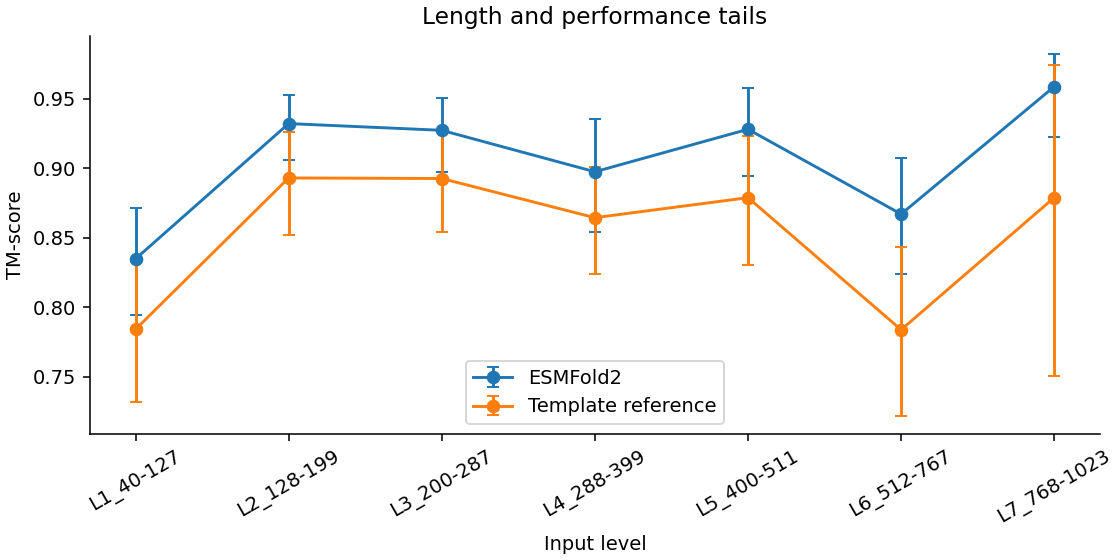

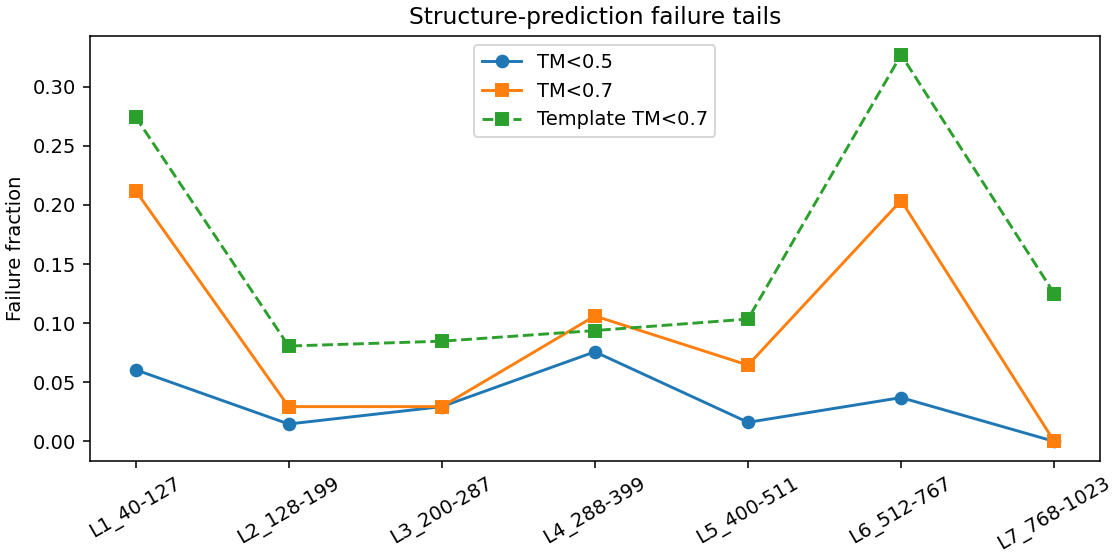

In [11]:
display(tails);display(long_tertiles);display(long_statistics);display(curves);plot_curve(curves,'Length and performance tails')
fig,ax=plt.subplots(figsize=(8,4),layout='constrained');ax.plot(tails.level,tails.failure_below_half,'o-',label='TM<0.5');ax.plot(tails.level,tails.failure_below_seven_tenths,'s-',label='TM<0.7');ax.plot(tails.level,tails.reference_failure_below_seven_tenths,'s--',label='Template TM<0.7');ax.set(ylabel='Failure fraction',title='Structure-prediction failure tails');ax.tick_params(axis='x',rotation=30);ax.legend();buffer=io.BytesIO();fig.savefig(buffer,format='png',dpi=140);plt.close(fig);display(Image(data=buffer.getvalue()))


## 6. What the agent decided, and why

State the result supported by the calculated input population and controls.


In [12]:
effect=stats.spearmanr(long_arm['len'],long_arm.tm_native.lt(.7)) if len(long_arm)>=30 else None;decision='The long-chain arm has an increasing failure fraction.' if effect is not None and effect.statistic>0 and effect.pvalue<.05 else 'The long-chain failure-fraction trend is unresolved at p<0.05.'
print(decision)
print('Acquisition population:',len(entity_ids),'evaluated population:',len(measurements),'primary-range population:',len(primary))
output=ROOT/'test-03';output.mkdir(parents=True,exist_ok=True)
features.to_csv(output/'axis_levels.csv',index=False);measurements.to_csv(output/'scores.csv',index=False);curves.to_csv(output/'curves.csv',index=False);regression.to_csv(output/'regression.csv',index=False);tails.to_csv(output/'tails.csv',index=False);stratified.to_csv(output/'homology_controls.csv',index=False);associations.to_csv(output/'associations.csv',index=False);long_tertiles.to_csv(output/'long_arm_tertiles.csv',index=False)
(output/'additional_controls.json').write_text(json.dumps({'univariate':univariate,'model_reference_interaction':interaction,'long_arm':long_statistics},indent=2))
receipt={'analysis_id':'esmfold2-opus-r2/test-03','completed':True,'host':socket.gethostname(),'input_population':len(entity_ids),'evaluated_population':len(measurements),'new_inference_executed':inferred_target_count>0,'new_inference_targets':inferred_target_count,'verified_prediction_targets':len(measurements),'input_manifest_sha256':sha256_file(manifest_path),'model_settings':settings,'model_checkpoint':checkpoint_signature,'decision':decision}
(output/'CALCULATION_RECEIPT.json').write_text(json.dumps(receipt,indent=2))


The long-chain failure-fraction trend is unresolved at p<0.05.
Acquisition population: 401 evaluated population: 400 primary-range population: 384


901